# Question 1

Normal mode example Lecture 6, plot sum of first 40 modes at t=1.5, 5, 10. Length of string is 20, velocity=3, location of source xs=8. For x axis, discretize this into units of length 0.1. Use the same expression for F(omegan) and the normal mode summation on slide 26 (the # in the lower corner of Lecture 6). Use 1 for value of tau in the F(omegan) eq. Time slice at 1.5 seconds should be identical to figure on slide 27, but what are changes at 5 and 10 seconds.

In [ ]:
import numpy as np
import matplotlib.pylab as plt

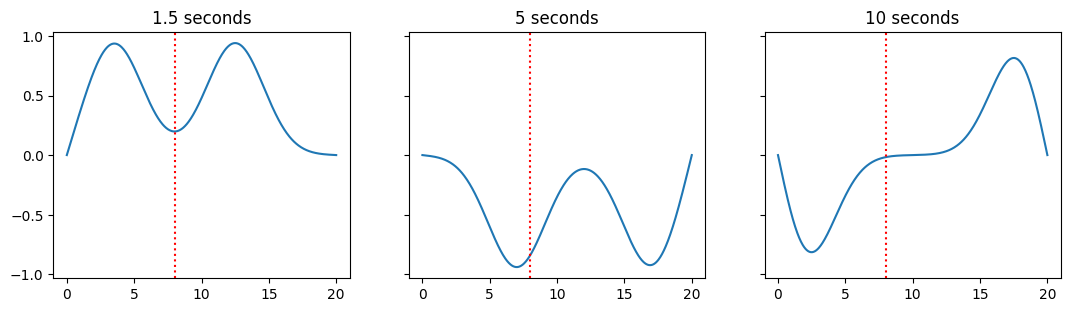

In [ ]:
L = 20.0
c = 3.0
xs = 8.0
t1 = 1.5
t2 = 5
t3 = 10
x = np.linspace(0, L, 600)

def mode_sum(x, xs, t, n_modes=40, tau_src=1, L=20.0, c=3.0):
    u = np.zeros_like(x)
    for n in range(1, n_modes + 1):
        omegan = n * np.pi * c / L
        An = np.sin(n * np.pi * xs / L) * np.exp(-(omegan * tau_src) ** 2 / 4)
        Un = np.sin(n * np.pi * x / L)
        u += An * Un * np.cos(omegan * t)
    return u

u1 = mode_sum(x, xs, t1)
u2 = mode_sum(x, xs, t2)
u3 = mode_sum(x, xs, t3)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, t in zip(axes, [t1, t2, t3]):
    ax.plot(x, mode_sum(x, xs, t))
    ax.set_title(f"{t} seconds")
    ax.axvline(xs, color="red", linestyle=":")

Each of these figures is the sum of 40 nodes. This shows the travel patterns of the waves developing and interacting over time. So, the waves interacted after 5 seconds and created the shape at 10 seconds.

# Question 3a

Use obspy taup function. Create version of figure 4.19 using ak135 velocity model with 0.1 degree grid spacing and a source depth of 40 km.

In [ ]:
%pip install obspy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 45.2 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
from obspy.taup import TauPyModel
import numpy as np
import random

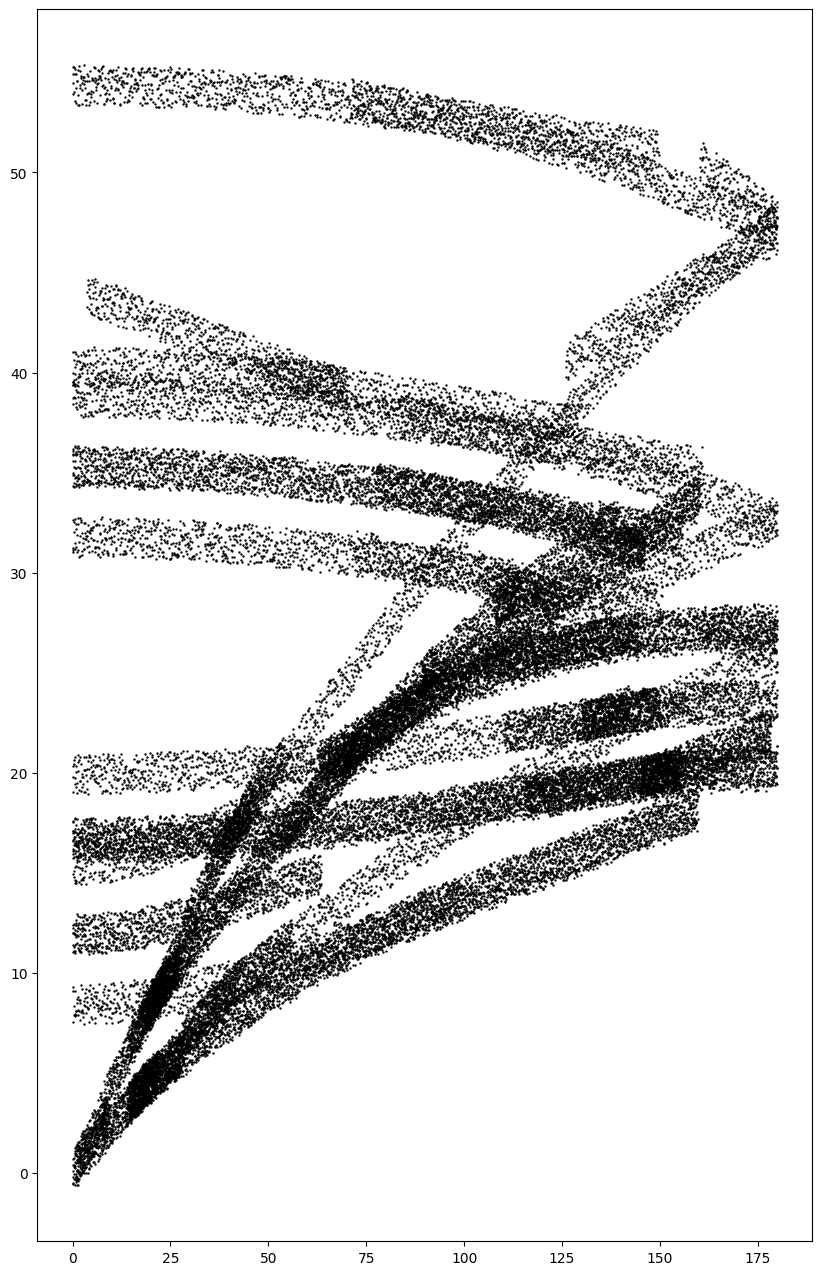

In [ ]:
model_ak135 = TauPyModel(model="ak135")

random.seed(40)

distance_range = np.arange(0, 180, 0.1)
depth = 40

all_distances = []
all_times = []

for distance in distance_range:
    arrivals = model_ak135.get_travel_times(source_depth_in_km=depth, distance_in_degree=distance)
    for arrival in arrivals:
      time = (arrival.time + random.randint(-60, +60)) / 60
      all_distances.append(distance)
      all_times.append(time)

plt.figure(figsize=(10,16))
plt.scatter(all_distances, all_times, s=0.5, c='black')


#arrivals = model_ak135.get_travel_times(source_depth_in_km=40, distance_in_degree=5)
#Numarrivals = len(arrivals)
#Arrivaltime = arrivals[0].time
# can loop the number of arrivals and extract the arrival times in sequential order.
# You will want to plot each theoretical arrival as a dot rather than a line

# Question 3b

Find broadband station (HHZ) that is roughly 90 deg away from an earthquake of magnitude 7.5 out to 1 hr. Label any of the theoretical phase arrivals from taup on your plt. Play around with filtering to observe additional arrivals.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from obspy.clients.fdsn import Client

In [ ]:
client = Client("EARTHSCOPE")
print(client)

FDSN Webservice Client (base url: https://service.earthscope.org)
Available Services: 'dataselect' (v1.1.81), 'station' (v1.1.58)

Use e.g. client.help('dataselect') for the
parameter description of the individual services
or client.help() for parameter description of
all webservices.


In [ ]:
client_events = Client("USGS")

events = client_events.get_events(
    starttime=UTCDateTime("2025-07-28"),
    endtime=UTCDateTime("2025-07-30"),
    minmagnitude=8.7,
    maxmagnitude=8.9,
)
print(events.__str__(print_all=True))

1 Event(s) in Catalog:
2025-07-29T23:24:52.483000Z | +52.495, +160.239 | 8.8  mww | manual


In [ ]:
#https://earthquake.usgs.gov/earthquakes/eventpage/us6000qw60/executive
inventory_box = client.get_stations(
    network="IU,II,US,PB",
    channel="HHZ",
    starttime=UTCDateTime("2025-07-01"),
    endtime=UTCDateTime("2025-07-30"),
    latitude=52.49, longitude=160.2,
    minradius=88,                 # degrees
    maxradius=92,                 # degrees
    level="station",
)
print(inventory_box)

Inventory created at 2026-10-09T11:03:21.644800Z
	Created by: EarthScope WEB SERVICE: fdsnws-station | version: 1.1.58
		    https://service.earthscope.org/fdsnws/station/1/query?starttime=202...
	Sending institution: EarthScope (EarthScope)
	Contains:
		Networks (1):
			II
		Stations (1):
			II.CMLA (Cha de Macela, Sao Miguel Island, Azores)
		Channels (0):



/usr/local/lib/python3.13/dist-packages/obspy/clients/fdsn/client.py:257: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)
/tmp/ipykernel_1790/1189552003.py:12: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st1 = client_iris.get_waveforms(


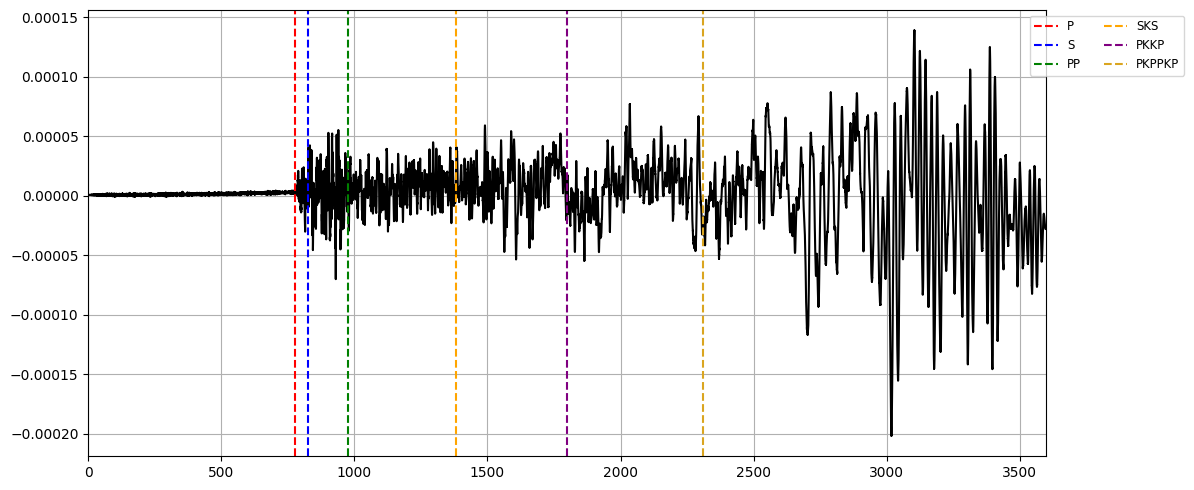

In [ ]:
# https://earthquake.usgs.gov/earthquakes/eventpage/us6000qw60/executive
# https://ds.iris.edu/mda/II/CMLA/

client_iris = Client("IRIS")

event1 = events[0]
origin1 = event1.preferred_origin() or event1.origins[0]
magnitude1 = event1.preferred_magnitude() or event1.magnitudes[0]
t1 = origin1.time

# fetch
st1 = client_iris.get_waveforms(
    network="II", station="CMLA", location="10", channel="HHZ",
    starttime=t1, endtime=t1 + 3600,
    attach_response=True
)

st1.remove_response(output="VEL")
tr1 = st1[0]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(tr1.times(), tr1.data, color="black")
ax.grid(True)
ax.set_xlim(0, 3600)

# Plot theoretical arrivals
ax.axvline(775, color="red", linestyle="--", label="P")
ax.axvline(825, color="b", linestyle="--", label="S")
ax.axvline(975, color="g", linestyle="--", label="PP")
ax.axvline(1380, color="orange", linestyle="--", label="SKS")
ax.axvline(1800, color="purple", linestyle="--", label="PKKP")
ax.axvline(2310, color="goldenrod", linestyle="--", label="PKPPKP")


# Add legend and adjust layout before showing the plot
ax.legend(loc='upper right', fontsize='small', ncol=2, bbox_to_anchor=(1.15, 1))
plt.tight_layout()
plt.show()

# Question 3c

Compute and plt the time diff between ak135 and PREM for only P wave arrivals betwn 6 and 90 deg at 0.1 deg intervals from a source at 40 km. Futhermore, find P wave depth curves for both PREM and AK135 and comment on the differences between them and how they may relate to your travel time difference curve.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from obspy.taup import TauPyModel

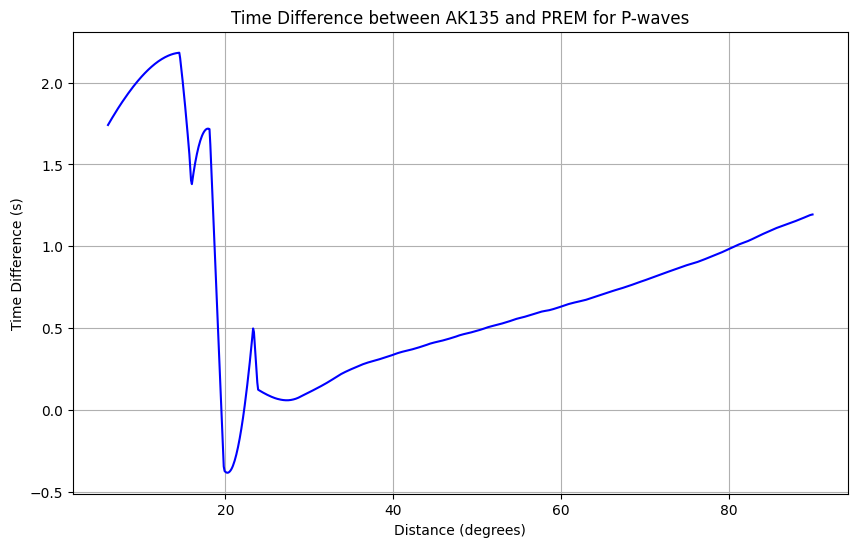

In [ ]:
# Load the ak135 and PREM velocity models
model_ak135 = TauPyModel(model="ak135")
model_prem = TauPyModel(model="prem")

# Define parameters
source_depth = 40
distance_range = np.arange(6, 90.1, 0.1)
phase = ["P"]

# Lists to store results
distance_values = []
time_differences = []
arrival_times_ak135 = []
arrival_times_prem = []

for distance in distance_range:
  parrival_prem = model_prem.get_travel_times(source_depth_in_km=source_depth, distance_in_degree=distance, phase_list=phase)
  parrival_ak135 = model_ak135.get_travel_times(source_depth_in_km=source_depth, distance_in_degree=distance, phase_list=phase)

  if parrival_prem and parrival_ak135:
    time_ak135 = parrival_ak135[0].time
    time_prem = parrival_prem[0].time
    time_diff = time_ak135 - time_prem

    distance_values.append(distance)
    time_differences.append(time_diff)
    arrival_times_ak135.append(time_ak135)
    arrival_times_prem.append(time_prem)

#plot time difference
plt.figure(figsize=(10, 6))
plt.plot(distance_values, time_differences, linestyle='-', color='b')
plt.xlabel('Distance (degrees)')
plt.ylabel('Time Difference (s)')
plt.title('Time Difference between AK135 and PREM for P-waves')
plt.grid(True)
plt.show()

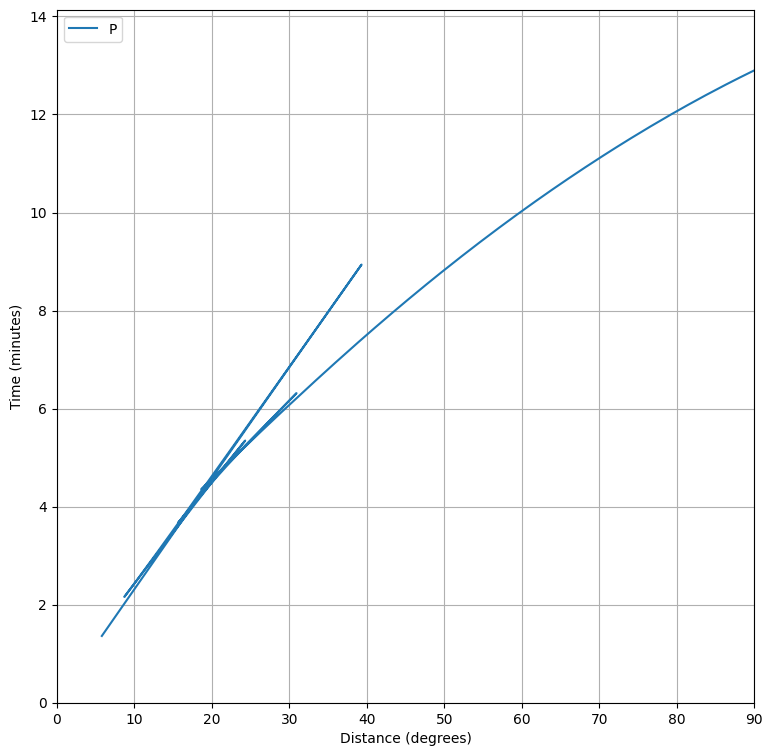

In [73]:
from obspy.taup import plot_travel_times
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 9))
ax = plot_travel_times(source_depth=40, max_degrees=90, model="PREM", phase_list=["P"],
                       ax=ax, fig=fig)

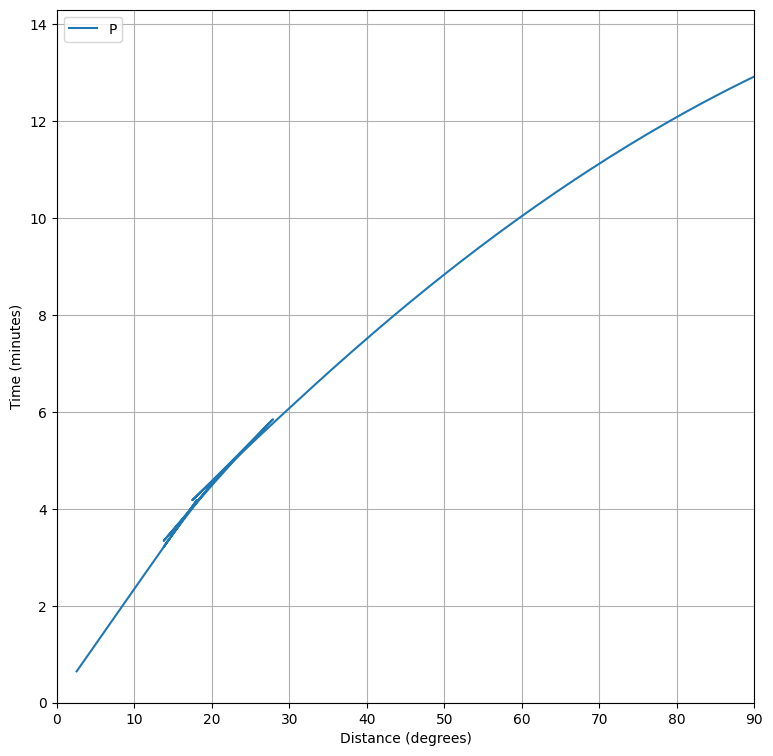

In [74]:
fig, ax = plt.subplots(figsize=(9, 9))
ax = plot_travel_times(source_depth=40, max_degrees=90, model="AK135", phase_list=["P"],
                       ax=ax, fig=fig)

[TauP Velocity plot of AK135 versus PREM](https://taup.readthedocs.io/en/latest/taup_velplot.html#taup-velplot) \
For differences seen between the velocity depth curves for the P, you can look at the blue line on the depth curve in the linked image. \
The upper mantle velocity, around 200 km to 600 km, has sharp velocity increases. The AK135 model uses a smoother represenation versus the PREM has more sharp jumps. This is because the AK135 model is designed to match travel times of real earthquake data, while PREM is a representation of a perfect earth. \
There is a clearer low velocity zone at depths of 80-220 km in one model, the PREM model I believe.